# 6T SRAM Cell: Static Noise Margin (Read and Hold)
A Python model of a 6-transistor SRAM cell using square-law MOSFET equations. It solves each half-cell's voltage transfer curve, builds the butterfly plot, and extracts the static noise margin (SNM) with the 45-degree method. It then shows how SNM changes with supply voltage and with the cell ratio (pull-down strength / access strength).

**Tools:** Python (NumPy, SciPy, Matplotlib). Runs in Google Colab with no installs.

Author: Kiranmayee Vaddepally, M.Tech, Quantum and Solid State Devices, IIT Hyderabad.

**Important:** the transistor parameters are illustrative round numbers, not a real technology. The results show trends and the method, not silicon-accurate margins.

## 1. Inputs and model
Change the values in the first block to explore. `KN`, `KP` are mu*Cox (A/V²); `VTN`, `VTP` are threshold voltage magnitudes (V). Transistor strength is set by W/L.

In [5]:
import numpy as np
from scipy.optimize import brentq

# ---- Inputs (illustrative square-law parameters, NOT a real technology) ----
KN, KP = 300e-6, 120e-6      # k' = mu*Cox  [A/V^2]
VTN, VTP = 0.35, 0.35        # threshold magnitudes [V]

def nmos(vgs, vds, wl):
    """Square-law NMOS drain current (vds may be any sign handled by caller)."""
    vov = vgs - VTN
    if vov <= 0 or vds <= 0: return 0.0
    if vds < vov: return KN*wl*(vov*vds - 0.5*vds**2)
    return 0.5*KN*wl*vov**2

def pmos(vsg, vsd, wl):
    vov = vsg - VTP
    if vov <= 0 or vsd <= 0: return 0.0
    if vsd < vov: return KP*wl*(vov*vsd - 0.5*vsd**2)
    return 0.5*KP*wl*vov**2

def vtc(vin, vdd, wl_pd, wl_pu, wl_ax, wl_on):
    """Output of one cell half-inverter. Access NMOS (gate=vdd*wl_on, bitline=vdd)
    injects current into the output node when the wordline is on."""
    def f(vout):
        i_pu = pmos(vdd - vin, vdd - vout, wl_pu)
        i_ax = nmos(vdd*wl_on - vout, vdd - vout, wl_ax) if wl_on else 0.0
        i_pd = nmos(vin, vout, wl_pd)
        return i_pu + i_ax - i_pd
    return brentq(f, 0.0, vdd)  # f(0)>=0, f(vdd)<=0

def snm(vdd, beta=2.0, pr=1.0, read=True, n=401):
    """Static noise margin via the 45-degree rotation method.
    beta = (W/L)pulldown/(W/L)access (cell ratio), pr = (W/L)pullup/(W/L)access."""
    wl_ax = 1.0
    wl_pd, wl_pu = beta*wl_ax, pr*wl_ax
    vin = np.linspace(0, vdd, n)
    vout = np.array([vtc(v, vdd, wl_pd, wl_pu, wl_ax, 1.0 if read else 0.0) for v in vin])
    # curve 1: (x, y) = (vin, vout); curve 2 is its mirror: (vout, vin)
    u1, v1 = (vin+vout)/np.sqrt(2), (vout-vin)/np.sqrt(2)
    u2, v2 = (vout+vin)/np.sqrt(2), (vin-vout)/np.sqrt(2)
    # square corners sit on the two curves at equal v; the diagonal runs along u
    o1, o2 = np.argsort(v1), np.argsort(v2)
    v = np.linspace(max(v1.min(), v2.min()), min(v1.max(), v2.max()), 4001)
    d = np.interp(v, v1[o1], u1[o1]) - np.interp(v, v2[o2], u2[o2])
    return min(d.max(), -d.min())/np.sqrt(2), vin, vout

def switching_threshold(vdd, wl_pd, wl_pu):
    vin = np.linspace(0, vdd, 2001)
    vout = np.array([vtc(v, vdd, wl_pd, wl_pu, 1.0, 0.0) for v in vin])
    return vin[np.argmin(np.abs(vout - vin))]

## 2. Check: a balanced inverter should switch at VDD/2
With KN·Wn = KP·Wp the switching threshold of the inverter must equal VDD/2. This is a simple test that the transistor equations and the solver are correct.

In [6]:
for vdd in (0.8, 1.0, 1.2):
    vm = switching_threshold(vdd, 1.0, KN/KP)
    print(f"VDD = {vdd:.1f} V  ->  switching threshold = {vm:.3f} V  (expected {vdd/2:.3f} V)")

VDD = 0.8 V  ->  switching threshold = 0.400 V  (expected 0.400 V)
VDD = 1.0 V  ->  switching threshold = 0.500 V  (expected 0.500 V)
VDD = 1.2 V  ->  switching threshold = 0.600 V  (expected 0.600 V)


## 3. Butterfly curves (VDD = 1.0 V, cell ratio 2)
The side of the largest square that fits inside the smaller lobe is the SNM. Read SNM is lower than hold SNM because the access transistor disturbs the node storing 0.

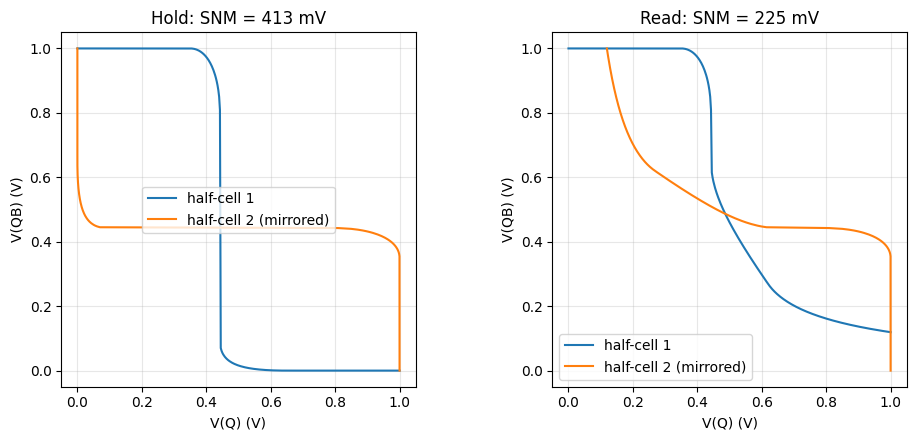

In [7]:
import matplotlib.pyplot as plt
VDD, BETA = 1.0, 2.0
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, read, name in zip(axs, (False, True), ("Hold", "Read")):
    s, vin, vout = snm(VDD, beta=BETA, read=read)
    ax.plot(vin, vout, label="half-cell 1")
    ax.plot(vout, vin, label="half-cell 2 (mirrored)")
    ax.set_title(f"{name}: SNM = {s*1000:.0f} mV")
    ax.set_xlabel("V(Q) (V)"); ax.set_ylabel("V(QB) (V)")
    ax.set_aspect("equal"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## 4. SNM versus supply voltage and cell ratio

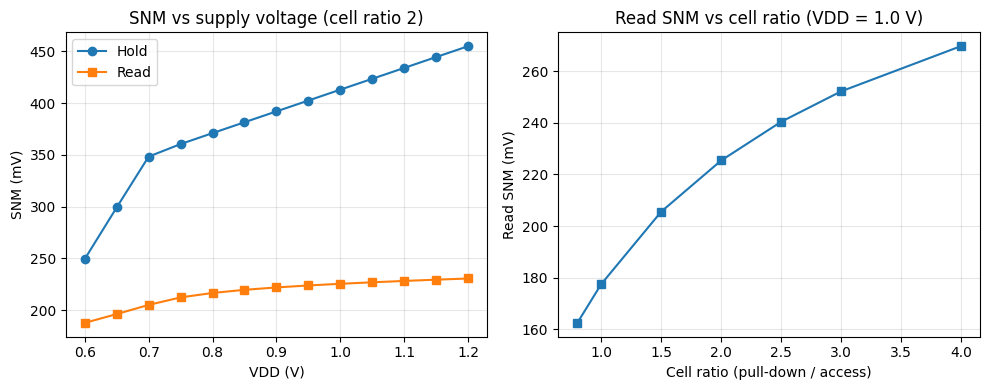

In [8]:
vdds = np.linspace(0.6, 1.2, 13)
hold = [snm(v, read=False)[0] for v in vdds]
read = [snm(v, read=True)[0] for v in vdds]
betas = np.array([0.8, 1, 1.5, 2, 2.5, 3, 4])
rd_beta = [snm(1.0, beta=b)[0] for b in betas]

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].plot(vdds, np.array(hold)*1000, "o-", label="Hold")
axs[0].plot(vdds, np.array(read)*1000, "s-", label="Read")
axs[0].set_xlabel("VDD (V)"); axs[0].set_ylabel("SNM (mV)"); axs[0].legend(); axs[0].grid(alpha=.3)
axs[0].set_title("SNM vs supply voltage (cell ratio 2)")
axs[1].plot(betas, np.array(rd_beta)*1000, "s-")
axs[1].set_xlabel("Cell ratio (pull-down / access)"); axs[1].set_ylabel("Read SNM (mV)"); axs[1].grid(alpha=.3)
axs[1].set_title("Read SNM vs cell ratio (VDD = 1.0 V)")
plt.tight_layout(); plt.show()

## 5. What this shows
- Hold SNM is larger than read SNM at every supply voltage, because the access transistor fights the pull-down on the node storing 0 during a read.
- Read SNM improves as the cell ratio increases: a stronger pull-down relative to the access transistor keeps the 0 node lower during a read.
- Both margins shrink as VDD is lowered, which is why low-voltage SRAM operation is hard.

## 6. Assumptions and limitations
- Long-channel square-law model: no channel-length modulation, velocity saturation, subthreshold current or short-channel effects.
- Parameters are illustrative, not from a real process; there is no process variation or temperature dependence.
- Only read and hold margins are computed. Write margin is not modelled.
- Without channel-length modulation the inverter gain is unrealistically high, so hold SNM (about 0.4 × VDD) is larger than real cells show. Trends are meaningful; absolute values are not.
- Below about 0.7 V (2 × threshold voltage) the square-law model is least reliable, which causes the kink in the hold curve.
- This is a first-principles study of the method, not a replacement for transistor-level SPICE simulation with a real technology model.